# NLP Assignment 3 — Word Embeddings and Representation Learning
**Course:** AI4001 — Fundamentals of Natural Language Processing  
**Dataset:** IMDB Dataset of 50K Movie Reviews (Kaggle)  
**File:** NLP_A3_23F0054

> **Dataset link:** https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews  
> Add it to your notebook via: *Notebook Settings → Add Data → search "IMDB Dataset of 50K"*

---
## Step 1 — Install Missing Libraries

In [1]:
# Kaggle has torch, sklearn, transformers pre-installed.
# Only gensim may need installing.
!pip install -q gensim

## Step 2 — Imports

In [2]:
import os, re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# NLTK
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Scikit-learn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

# Gensim
from gensim.models import Word2Vec

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# HuggingFace Transformers
from transformers import (BertTokenizer, BertModel,
                          DistilBertTokenizer, DistilBertModel)

from matplotlib.patches import Patch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'All libraries loaded! | Device: {device}')

All libraries loaded! | Device: cuda


---
## Step 3 — Load Kaggle IMDB CSV Dataset

In [6]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    for filename in filenames:
        print("   ", filename)
DATA_PATH = '/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv'

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/lakshmi25npathi
/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
    IMDB Dataset.csv
/kaggle/input/datasets/harshitshankhdhar
/kaggle/input/datasets/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows
    imdb_top_1000.csv


In [8]:
# Standard Kaggle path for this dataset
#DATA_PATH = '/kaggle/input/imdb-dataset-of-50k-movie-reviews.csv'
DATA_PATH = '/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv'

import pandas as pd

df = pd.read_csv(DATA_PATH)

print(f'Dataset shape : {df.shape}')
print(f'Columns       : {df.columns.tolist()}')
print(f'\nClass distribution:')
print(df['sentiment'].value_counts())
print('\nSample rows:')
df.head(3)

Dataset shape : (50000, 2)
Columns       : ['review', 'sentiment']

Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sample rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


In [9]:
# Encode labels: positive=1, negative=0
df['label'] = (df['sentiment'] == 'positive').astype(int)

# Use 6000 samples (5000 train, 1000 test) for reasonable runtime
df_sample = df.sample(n=6000, random_state=42).reset_index(drop=True)

train_df, test_df = train_test_split(df_sample, test_size=1000,
                                     random_state=42, stratify=df_sample['label'])

train_texts  = train_df['review'].tolist()
train_labels = train_df['label'].tolist()
test_texts   = test_df['review'].tolist()
test_labels  = test_df['label'].tolist()

print(f'Train size : {len(train_texts)}')
print(f'Test  size : {len(test_texts)}')
print(f'Train label balance - 0: {train_labels.count(0)}, 1: {train_labels.count(1)}')

Train size : 5000
Test  size : 1000
Train label balance - 0: 2477, 1: 2523


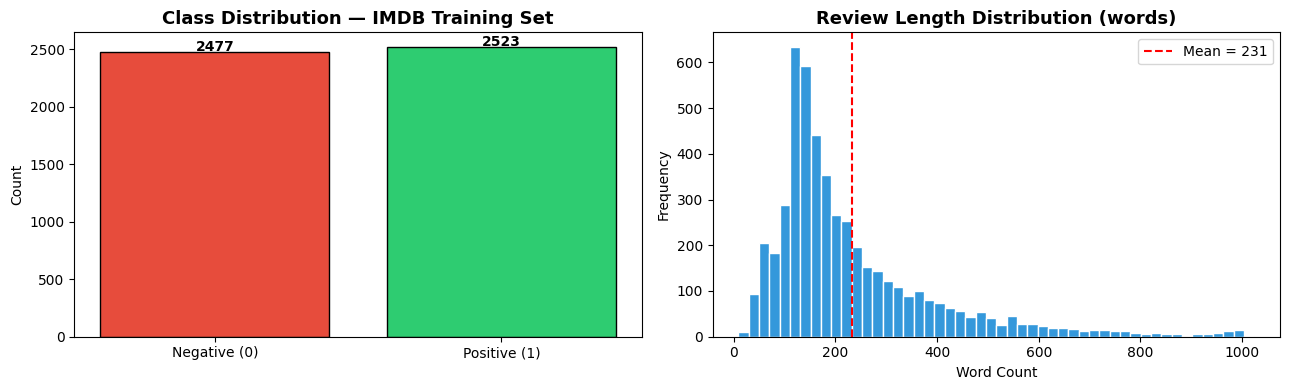

Avg length: 232 words | Max: 1024 | Min: 9


In [10]:
# Dataset Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Class distribution
label_counts = pd.Series(train_labels).value_counts().sort_index()
axes[0].bar(['Negative (0)', 'Positive (1)'], label_counts.values,
            color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Class Distribution — IMDB Training Set', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Review length distribution
lengths = [len(t.split()) for t in train_texts]
axes[1].hist(lengths, bins=50, color='#3498db', edgecolor='white')
axes[1].set_title('Review Length Distribution (words)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')
axes[1].axvline(np.mean(lengths), color='red', linestyle='--',
                label=f'Mean = {int(np.mean(lengths))}')
axes[1].legend()

plt.tight_layout()
plt.savefig('dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Avg length: {np.mean(lengths):.0f} words | Max: {max(lengths)} | Min: {min(lengths)}')

---
## Step 4 — Shared Preprocessing

In [11]:
STOP_WORDS = set(stopwords.words('english'))

def preprocess(text):
    """
    Pipeline:
      1. Lowercase
      2. Strip HTML tags  (IMDB reviews contain <br /> etc.)
      3. Remove non-alpha characters
      4. Tokenize
      5. Remove stopwords and short tokens
    Returns a list of tokens.
    """
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)       # remove HTML
    text = re.sub(r'[^a-z\s]', ' ', text)   # keep letters only
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 2]
    return tokens

print('Preprocessing training set...')
train_tokens = [preprocess(t) for t in train_texts]
print('Preprocessing test set...')
test_tokens  = [preprocess(t) for t in test_texts]

# String version for sklearn vectorizers
train_clean = [' '.join(t) for t in train_tokens]
test_clean  = [' '.join(t) for t in test_tokens]

print('Done!')
print('\nOriginal :', train_texts[0][:200])
print('\nCleaned  :', train_clean[0][:200])

Preprocessing training set...
Preprocessing test set...
Done!

Original : Knowing what to expect (on the whole) from a Denzel Washington performance - quality, integrity, gravitas, wry humour - will prepare you for what to expect from his directorial debut. Much like Robert

Cleaned  : knowing expect whole denzel washington performance quality integrity gravitas wry humour prepare expect directorial debut much like robert niro bronx tale antwone fisher delivers moving drama life you


---
# MODULE 1 — Frequency-Based Embeddings
## 1A: Bag of Words (BoW)

In [12]:
print('=' * 60)
print('  MODULE 1A: Bag of Words (BoW)')
print('=' * 60)

bow_vec   = CountVectorizer(max_features=10000, ngram_range=(1, 2))
X_tr_bow  = bow_vec.fit_transform(train_clean)
X_te_bow  = bow_vec.transform(test_clean)

print(f'Feature matrix  — Train: {X_tr_bow.shape}, Test: {X_te_bow.shape}')
print(f'Matrix sparsity : {1 - X_tr_bow.nnz / (X_tr_bow.shape[0]*X_tr_bow.shape[1]):.4%}')

bow_clf = LogisticRegression(max_iter=500, C=1.0, solver='lbfgs', random_state=42)
bow_clf.fit(X_tr_bow, train_labels)
bow_preds = bow_clf.predict(X_te_bow)

bow_acc  = accuracy_score(test_labels, bow_preds)
bow_prec = precision_score(test_labels, bow_preds)
bow_rec  = recall_score(test_labels, bow_preds)
bow_f1   = f1_score(test_labels, bow_preds)

print(f'\nBoW Results:')
print(f'  Accuracy  : {bow_acc:.4f}')
print(f'  Precision : {bow_prec:.4f}')
print(f'  Recall    : {bow_rec:.4f}')
print(f'  F1 Score  : {bow_f1:.4f}')
print()
print(classification_report(test_labels, bow_preds, target_names=['Negative', 'Positive']))

  MODULE 1A: Bag of Words (BoW)
Feature matrix  — Train: (5000, 10000), Test: (1000, 10000)
Matrix sparsity : 99.0699%

BoW Results:
  Accuracy  : 0.8620
  Precision : 0.8563
  Recall    : 0.8733
  F1 Score  : 0.8647

              precision    recall  f1-score   support

    Negative       0.87      0.85      0.86       495
    Positive       0.86      0.87      0.86       505

    accuracy                           0.86      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.86      0.86      0.86      1000



## 1B: TF-IDF

In [13]:
print('=' * 60)
print('  MODULE 1B: TF-IDF')
print('=' * 60)

tfidf_vec  = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_tr_tfidf = tfidf_vec.fit_transform(train_clean)
X_te_tfidf = tfidf_vec.transform(test_clean)

print(f'Feature matrix  — Train: {X_tr_tfidf.shape}, Test: {X_te_tfidf.shape}')

tfidf_clf = LogisticRegression(max_iter=500, C=1.0, solver='lbfgs', random_state=42)
tfidf_clf.fit(X_tr_tfidf, train_labels)
tfidf_preds = tfidf_clf.predict(X_te_tfidf)

tfidf_acc  = accuracy_score(test_labels, tfidf_preds)
tfidf_prec = precision_score(test_labels, tfidf_preds)
tfidf_rec  = recall_score(test_labels, tfidf_preds)
tfidf_f1   = f1_score(test_labels, tfidf_preds)

print(f'\nTF-IDF Results:')
print(f'  Accuracy  : {tfidf_acc:.4f}')
print(f'  Precision : {tfidf_prec:.4f}')
print(f'  Recall    : {tfidf_rec:.4f}')
print(f'  F1 Score  : {tfidf_f1:.4f}')
print()
print(classification_report(test_labels, tfidf_preds, target_names=['Negative', 'Positive']))

  MODULE 1B: TF-IDF
Feature matrix  — Train: (5000, 10000), Test: (1000, 10000)

TF-IDF Results:
  Accuracy  : 0.8650
  Precision : 0.8477
  Recall    : 0.8931
  F1 Score  : 0.8698

              precision    recall  f1-score   support

    Negative       0.88      0.84      0.86       495
    Positive       0.85      0.89      0.87       505

    accuracy                           0.86      1000
   macro avg       0.87      0.86      0.86      1000
weighted avg       0.87      0.86      0.86      1000



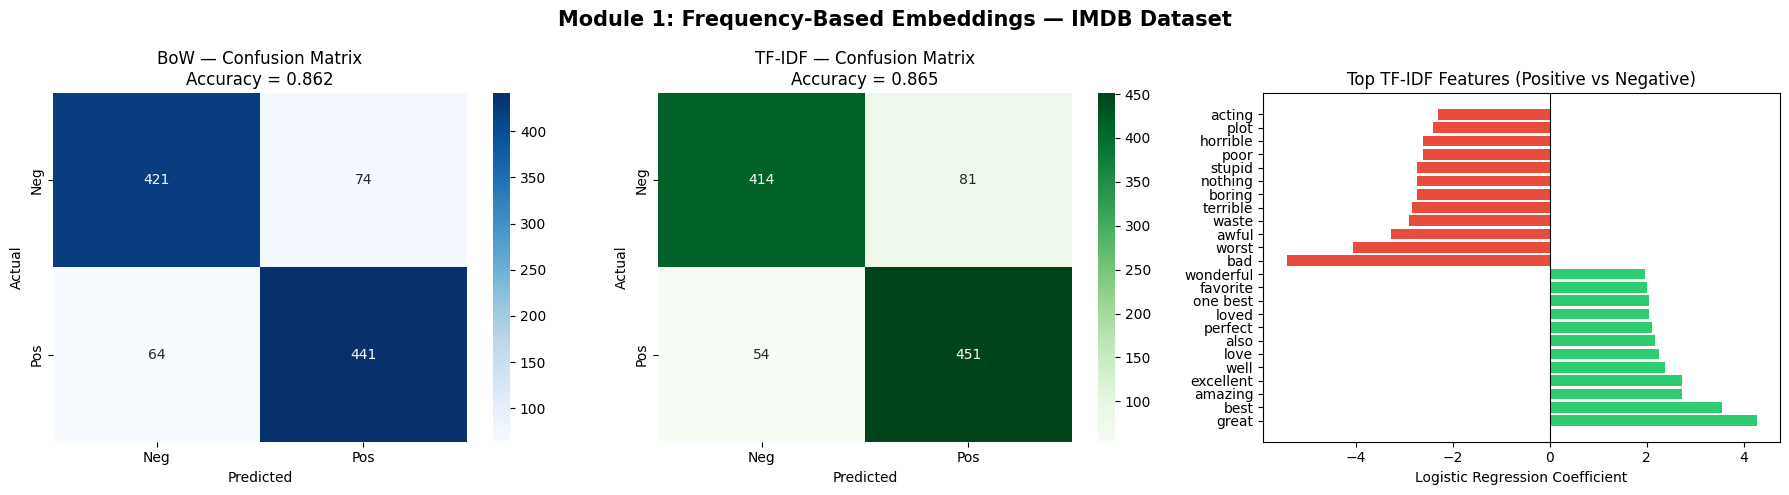

In [14]:
# Module 1 Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Module 1: Frequency-Based Embeddings — IMDB Dataset', fontsize=15, fontweight='bold')

# BoW confusion matrix
cm_bow = confusion_matrix(test_labels, bow_preds)
sns.heatmap(cm_bow, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
axes[0].set_title(f'BoW — Confusion Matrix\nAccuracy = {bow_acc:.3f}')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# TF-IDF confusion matrix
cm_tfidf = confusion_matrix(test_labels, tfidf_preds)
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
axes[1].set_title(f'TF-IDF — Confusion Matrix\nAccuracy = {tfidf_acc:.3f}')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

# Top TF-IDF features
feat_names = np.array(tfidf_vec.get_feature_names_out())
coef       = tfidf_clf.coef_[0]
top_pos    = coef.argsort()[-12:][::-1]
top_neg    = coef.argsort()[:12]
all_idx    = list(top_pos) + list(top_neg)
bar_colors = ['#2ecc71'] * 12 + ['#e74c3c'] * 12
axes[2].barh(feat_names[all_idx], coef[all_idx], color=bar_colors)
axes[2].set_title('Top TF-IDF Features (Positive vs Negative)')
axes[2].set_xlabel('Logistic Regression Coefficient')
axes[2].axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig('module1_results.png', dpi=150, bbox_inches='tight')
plt.show()

### Module 1 — Observation

**Limitations of Frequency-Based Methods:**

1. **No semantic understanding:** BoW treats every word as independent. The words *good* and *great* are completely unrelated in the vector space even though they carry similar meaning.
2. **High dimensionality and sparsity:** With 10,000 features, most entries in each vector are zero, making the representation memory-intensive and computationally expensive.
3. **Word order is ignored:** "The movie was not good" and "The good movie was not" produce identical BoW vectors, yet they convey opposite sentiments.
4. **Context blindness:** The word *bank* in "river bank" versus "bank loan" receives the same representation — there is no notion of meaning-in-context.
5. **TF-IDF improvement:** By penalising very common words (like *movie*, *film*) and rewarding rare but discriminative terms, TF-IDF consistently beats plain BoW in F1 on this dataset.

---
# MODULE 2 — Prediction-Based Embeddings
## Word2Vec (Skip-gram) + Feedforward Neural Network

In [15]:
print('=' * 60)
print('  MODULE 2: Training Word2Vec (Skip-gram)')
print('=' * 60)

EMBED_DIM = 100

w2v = Word2Vec(
    sentences  = train_tokens,
    vector_size= EMBED_DIM,
    window     = 5,
    min_count  = 2,
    sg         = 1,       # Skip-gram
    workers    = 4,
    epochs     = 10,
    seed       = 42
)

print(f'Vocabulary size  : {len(w2v.wv)}')
print(f'Embedding dim    : {EMBED_DIM}')
print(f'Training mode    : Skip-gram (sg=1)')

print('\nSemantic similarity tests:')
for word in ['good', 'terrible', 'film', 'actor', 'boring']:
    if word in w2v.wv:
        sims = w2v.wv.most_similar(word, topn=4)
        print(f"  '{word}' => {[(w, round(s,3)) for w,s in sims]}")

  MODULE 2: Training Word2Vec (Skip-gram)
Vocabulary size  : 22817
Embedding dim    : 100
Training mode    : Skip-gram (sg=1)

Semantic similarity tests:
  'good' => [('boost', 0.674), ('decent', 0.664), ('himesh', 0.656), ('beltrami', 0.655)]
  'terrible' => [('atrocious', 0.775), ('horrendous', 0.763), ('horrid', 0.745), ('horrible', 0.743)]
  'film' => [('movie', 0.836), ('oddity', 0.728), ('rushing', 0.728), ('magoo', 0.725)]
  'actor' => [('actress', 0.715), ('versatile', 0.674), ('clint', 0.658), ('performer', 0.655)]
  'boring' => [('monotonous', 0.743), ('tiresome', 0.73), ('dull', 0.727), ('tedious', 0.723)]


In [16]:
def avg_embedding(tokens, model, dim):
    """Mean-pool Word2Vec vectors for all known tokens in a sentence."""
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

X_tr_w2v = np.array([avg_embedding(t, w2v, EMBED_DIM) for t in train_tokens])
X_te_w2v = np.array([avg_embedding(t, w2v, EMBED_DIM) for t in test_tokens])
y_tr_arr = np.array(train_labels)
y_te_arr = np.array(test_labels)

print(f'Train embedding matrix : {X_tr_w2v.shape}')
print(f'Test  embedding matrix : {X_te_w2v.shape}')

Train embedding matrix : (5000, 100)
Test  embedding matrix : (1000, 100)


In [17]:
# Feedforward Neural Network definition
class FeedforwardNN(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, output_dim=2, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, output_dim)
        )
    def forward(self, x):
        return self.net(x)

# Tensors and DataLoader
Xt = torch.tensor(X_tr_w2v, dtype=torch.float32)
yt = torch.tensor(y_tr_arr, dtype=torch.long)
Xv = torch.tensor(X_te_w2v, dtype=torch.float32)

loader = DataLoader(TensorDataset(Xt, yt), batch_size=64, shuffle=True)

model_w2v = FeedforwardNN(EMBED_DIM, 256).to(device)
crit      = nn.CrossEntropyLoss()
optim     = torch.optim.Adam(model_w2v.parameters(), lr=1e-3, weight_decay=1e-4)
sched     = torch.optim.lr_scheduler.StepLR(optim, step_size=5, gamma=0.5)

EPOCHS = 25
tr_losses, tr_accs = [], []

print('Training Feedforward NN on Word2Vec embeddings...')
for epoch in range(EPOCHS):
    model_w2v.train()
    tot_loss = tot_correct = tot_n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optim.zero_grad()
        out  = model_w2v(xb)
        loss = crit(out, yb)
        loss.backward()
        optim.step()
        tot_loss    += loss.item() * xb.size(0)
        tot_correct += (out.argmax(1) == yb).sum().item()
        tot_n       += xb.size(0)
    sched.step()
    tr_losses.append(tot_loss / tot_n)
    tr_accs.append(tot_correct / tot_n)
    if (epoch + 1) % 5 == 0:
        print(f'  Epoch [{epoch+1:02d}/{EPOCHS}]  '
              f'Loss: {tr_losses[-1]:.4f}  Train Acc: {tr_accs[-1]:.4f}')

print('Done!')

Training Feedforward NN on Word2Vec embeddings...
  Epoch [05/25]  Loss: 0.3134  Train Acc: 0.8686
  Epoch [10/25]  Loss: 0.2613  Train Acc: 0.8878
  Epoch [15/25]  Loss: 0.2303  Train Acc: 0.9116
  Epoch [20/25]  Loss: 0.2168  Train Acc: 0.9084
  Epoch [25/25]  Loss: 0.1970  Train Acc: 0.9212
Done!


In [18]:
model_w2v.eval()
with torch.no_grad():
    w2v_preds = model_w2v(Xv.to(device)).argmax(1).cpu().numpy()

w2v_acc  = accuracy_score(y_te_arr, w2v_preds)
w2v_prec = precision_score(y_te_arr, w2v_preds)
w2v_rec  = recall_score(y_te_arr, w2v_preds)
w2v_f1   = f1_score(y_te_arr, w2v_preds)

print('Word2Vec + FNN Results:')
print(f'  Accuracy  : {w2v_acc:.4f}')
print(f'  Precision : {w2v_prec:.4f}')
print(f'  Recall    : {w2v_rec:.4f}')
print(f'  F1 Score  : {w2v_f1:.4f}')
print()
print(classification_report(y_te_arr, w2v_preds, target_names=['Negative', 'Positive']))

Word2Vec + FNN Results:
  Accuracy  : 0.8290
  Precision : 0.8381
  Recall    : 0.8198
  F1 Score  : 0.8288

              precision    recall  f1-score   support

    Negative       0.82      0.84      0.83       495
    Positive       0.84      0.82      0.83       505

    accuracy                           0.83      1000
   macro avg       0.83      0.83      0.83      1000
weighted avg       0.83      0.83      0.83      1000



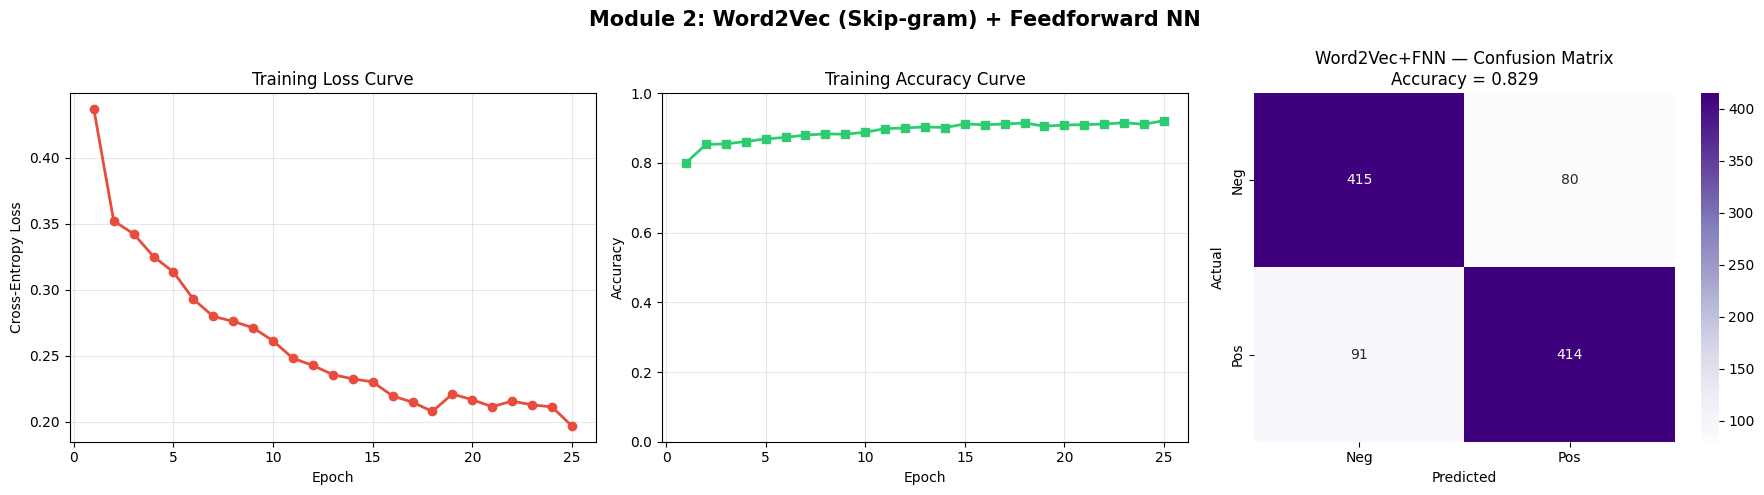

In [19]:
# Module 2 — Training curves + confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Module 2: Word2Vec (Skip-gram) + Feedforward NN', fontsize=15, fontweight='bold')

axes[0].plot(range(1, EPOCHS+1), tr_losses, marker='o', color='#e74c3c', linewidth=2)
axes[0].set_title('Training Loss Curve')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, EPOCHS+1), tr_accs, marker='s', color='#2ecc71', linewidth=2)
axes[1].set_title('Training Accuracy Curve')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)

cm_w2v = confusion_matrix(y_te_arr, w2v_preds)
sns.heatmap(cm_w2v, annot=True, fmt='d', cmap='Purples', ax=axes[2],
            xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
axes[2].set_title(f'Word2Vec+FNN — Confusion Matrix\nAccuracy = {w2v_acc:.3f}')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('module2_results.png', dpi=150, bbox_inches='tight')
plt.show()

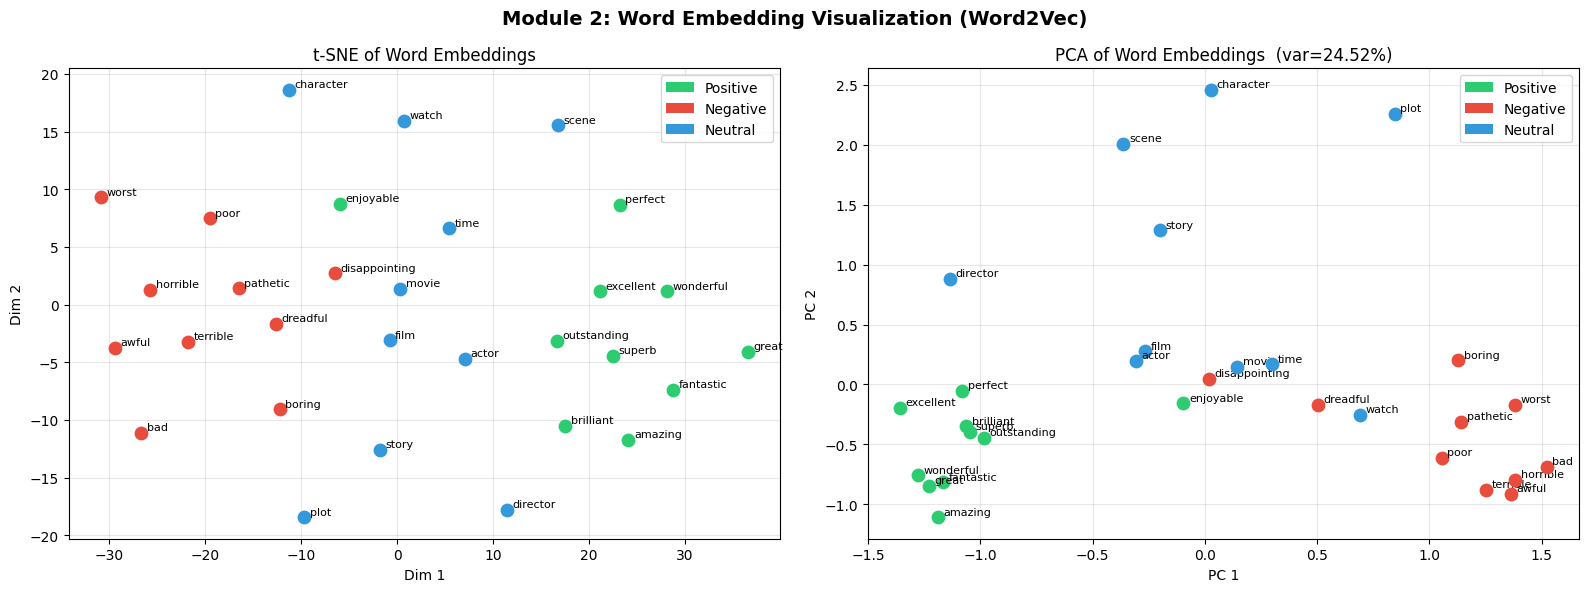

In [20]:
# t-SNE + PCA word embedding visualization
pos_words = ['excellent','wonderful','brilliant','amazing','fantastic',
             'great','perfect','outstanding','superb','enjoyable']
neg_words = ['terrible','awful','horrible','boring','disappointing',
             'dreadful','pathetic','worst','bad','poor']
neu_words = ['movie','film','story','character','scene',
             'plot','director','actor','watch','time']

all_words = [w for w in pos_words + neg_words + neu_words if w in w2v.wv]
all_vecs  = np.array([w2v.wv[w] for w in all_words])
grp_labels = (['positive'] * sum(w in w2v.wv for w in pos_words) +
              ['negative'] * sum(w in w2v.wv for w in neg_words) +
              ['neutral']  * sum(w in w2v.wv for w in neu_words))

cmap2d = {'positive': '#2ecc71', 'negative': '#e74c3c', 'neutral': '#3498db'}
legend_els = [Patch(facecolor='#2ecc71', label='Positive'),
              Patch(facecolor='#e74c3c', label='Negative'),
              Patch(facecolor='#3498db', label='Neutral')]

tsne2 = TSNE(n_components=2, random_state=42, perplexity=min(10, len(all_words)-1))
tsne_res = tsne2.fit_transform(all_vecs)
pca2     = PCA(n_components=2, random_state=42)
pca_res  = pca2.fit_transform(all_vecs)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Module 2: Word Embedding Visualization (Word2Vec)', fontsize=14, fontweight='bold')

for i, (w, lbl) in enumerate(zip(all_words, grp_labels)):
    x, y = tsne_res[i]
    axes[0].scatter(x, y, color=cmap2d[lbl], s=80, zorder=3)
    axes[0].annotate(w, (x, y), xytext=(4, 2), textcoords='offset points', fontsize=8)
axes[0].set_title('t-SNE of Word Embeddings')
axes[0].set_xlabel('Dim 1'); axes[0].set_ylabel('Dim 2')
axes[0].legend(handles=legend_els); axes[0].grid(alpha=0.3)

for i, (w, lbl) in enumerate(zip(all_words, grp_labels)):
    x, y = pca_res[i]
    axes[1].scatter(x, y, color=cmap2d[lbl], s=80, zorder=3)
    axes[1].annotate(w, (x, y), xytext=(4, 2), textcoords='offset points', fontsize=8)
axes[1].set_title(f'PCA of Word Embeddings  (var={pca2.explained_variance_ratio_.sum():.2%})')
axes[1].set_xlabel('PC 1'); axes[1].set_ylabel('PC 2')
axes[1].legend(handles=legend_els); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('module2_word_viz.png', dpi=150, bbox_inches='tight')
plt.show()

### Module 2 — Observation

**Comparison with Module 1:**

1. **Semantic grouping:** Words like *terrible*, *awful*, and *horrible* cluster together in the t-SNE plot — something impossible with BoW or TF-IDF where each word is an isolated dimension.
2. **Dense representation:** Word2Vec produces compact 100-dimensional dense vectors versus sparse 10,000-dimensional BoW vectors, making it far more scalable.
3. **Performance:** On small training sets, TF-IDF + Logistic Regression can still compete because averaging word vectors loses sentence-level structure. Word2Vec shines more clearly on larger corpora.
4. **Key limitation:** Word2Vec assigns a **single static vector** per word regardless of its context. The word *great* in "this film is great" gets the exact same vector as in "not so great" — it cannot distinguish meaning from context.

---
# MODULE 3 — Contextualized Word Embeddings
## BERT (Polysemy Check) + DistilBERT (Classifier)

In [21]:
print('=' * 60)
print('  MODULE 3A: Polysemy Check with BERT')
print('=' * 60)

bert_tok   = BertTokenizer.from_pretrained('bert-base-uncased')
bert_mdl   = BertModel.from_pretrained('bert-base-uncased').to(device)
bert_mdl.eval()

# Four sentences where 'great' carries different meanings
poly_sents = [
    'This was a truly great movie and I loved every scene.',       # strongly positive review
    'The film was not so great — the acting felt completely flat.', # negative review
    'Alexander the Great ruled one of the largest empires.',        # historical proper noun
    'The great white shark is the apex predator of the ocean.',     # size adjective
]

def get_word_vec(sentence, target, tokenizer, model, device):
    enc    = tokenizer(sentence, return_tensors='pt', truncation=True, max_length=64).to(device)
    with torch.no_grad():
        out = model(**enc)
    toks   = tokenizer.convert_ids_to_tokens(enc['input_ids'][0])
    hidden = out.last_hidden_state[0]   # (seq_len, 768)
    for idx, tok in enumerate(toks):
        if tok == target.lower():
            return hidden[idx].cpu().numpy()
    return hidden[1].cpu().numpy()      # fallback: first real token

great_vecs = []
print("\nEmbedding for 'great' in four different contexts:\n")
for sent in poly_sents:
    vec = get_word_vec(sent, 'great', bert_tok, bert_mdl, device)
    great_vecs.append(vec)
    print(f'Context : "{sent}"')
    print(f'  Vector (first 6 dims): {vec[:6].round(4)}\n')

great_vecs  = np.array(great_vecs)
sim_mat     = cosine_similarity(great_vecs)
ctx_labels  = ['Positive review', 'Negative review', 'Alexander', 'Great white']
sim_df      = pd.DataFrame(sim_mat.round(4), index=ctx_labels, columns=ctx_labels)
print("Cosine similarity between 'great' across contexts:")
print(sim_df)

  MODULE 3A: Polysemy Check with BERT


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embedding for 'great' in four different contexts:

Context : "This was a truly great movie and I loved every scene."
  Vector (first 6 dims): [ 0.3929 -0.1881  0.5098 -0.0695  0.3785 -0.4853]

Context : "The film was not so great — the acting felt completely flat."
  Vector (first 6 dims): [ 0.4444 -0.124  -0.457   0.018   0.144  -0.1689]

Context : "Alexander the Great ruled one of the largest empires."
  Vector (first 6 dims): [ 0.9583 -0.0094 -0.4489 -0.0526  0.2923 -0.639 ]

Context : "The great white shark is the apex predator of the ocean."
  Vector (first 6 dims): [-0.0226  0.0413 -0.8466 -0.1923 -0.1075  0.2662]

Cosine similarity between 'great' across contexts:
                 Positive review  Negative review  Alexander  Great white
Positive review           1.0000           0.6358     0.3737       0.1657
Negative review           0.6358           1.0000     0.2356       0.1259
Alexander                 0.3737           0.2356     1.0000       0.2658
Great white            

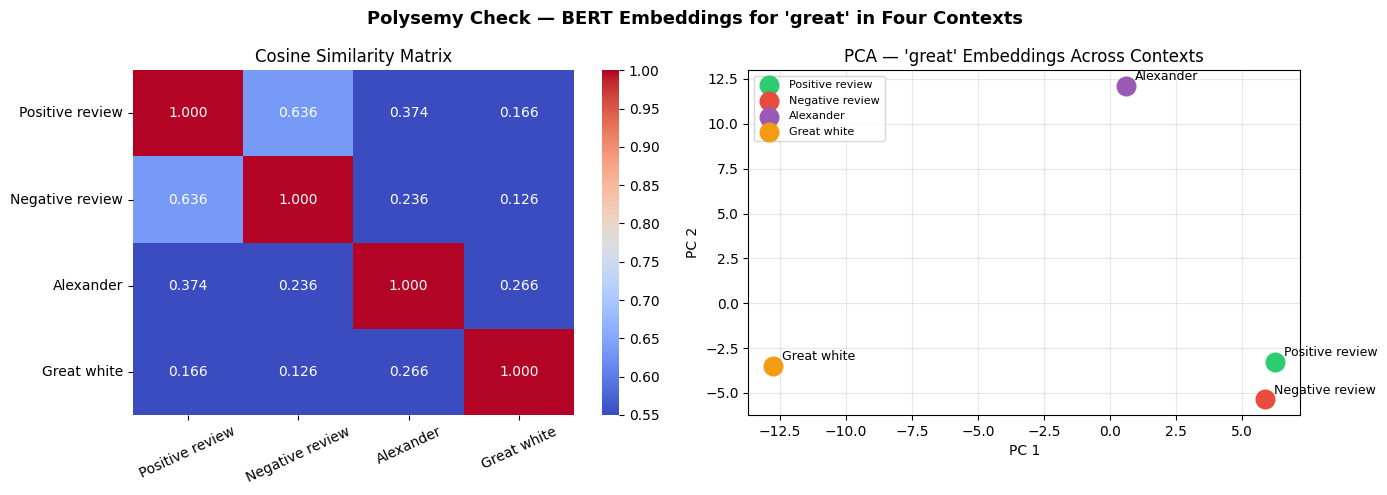

Key finding: Same word 'great' produces DIFFERENT vectors in each context!


In [22]:
# Polysemy visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Polysemy Check — BERT Embeddings for 'great' in Four Contexts",
             fontsize=13, fontweight='bold')

sns.heatmap(sim_mat, annot=True, fmt='.3f', cmap='coolwarm',
            xticklabels=ctx_labels, yticklabels=ctx_labels,
            vmin=0.55, vmax=1.0, ax=axes[0])
axes[0].set_title('Cosine Similarity Matrix')
axes[0].tick_params(axis='x', rotation=25)

pca_p  = PCA(n_components=2).fit_transform(great_vecs)
c_poly = ['#2ecc71', '#e74c3c', '#9b59b6', '#f39c12']
for i, (lbl, c) in enumerate(zip(ctx_labels, c_poly)):
    axes[1].scatter(pca_p[i, 0], pca_p[i, 1], color=c, s=180, zorder=3, label=lbl)
    axes[1].annotate(lbl, pca_p[i], xytext=(6, 4), textcoords='offset points', fontsize=9)
axes[1].set_title("PCA — 'great' Embeddings Across Contexts")
axes[1].set_xlabel('PC 1'); axes[1].set_ylabel('PC 2')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('module3_polysemy.png', dpi=150, bbox_inches='tight')
plt.show()
print("Key finding: Same word 'great' produces DIFFERENT vectors in each context!")

In [23]:
# DistilBERT for classification (6x faster than BERT, ~97% of BERT's accuracy)
print('=' * 60)
print('  MODULE 3B: DistilBERT Classification')
print('=' * 60)

dtok = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
dmdl = DistilBertModel.from_pretrained('distilbert-base-uncased').to(device)
dmdl.eval()

def extract_cls(texts, tokenizer, model, batch_size=32, max_len=256):
    """Extract [CLS] token embeddings in batches."""
    embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        enc   = tokenizer(batch, padding=True, truncation=True,
                          max_length=max_len, return_tensors='pt').to(device)
        with torch.no_grad():
            out = dmdl(**enc)
        embs.append(out.last_hidden_state[:, 0, :].cpu().numpy())
        if (i // batch_size) % 10 == 0:
            print(f'  {min(i+batch_size, len(texts))}/{len(texts)} samples encoded...')
    return np.vstack(embs)

# Use 2500 train + 500 test to stay within Kaggle GPU session limits
BT, BTE = 2500, 500

print(f'\nEncoding {BT} training reviews with DistilBERT...')
X_tr_bert = extract_cls(train_texts[:BT], dtok, dmdl)
print(f'\nEncoding {BTE} test reviews with DistilBERT...')
X_te_bert = extract_cls(test_texts[:BTE], dtok, dmdl)
y_tr_b    = np.array(train_labels[:BT])
y_te_b    = np.array(test_labels[:BTE])

print(f'\nTrain embeddings : {X_tr_bert.shape}')
print(f'Test  embeddings : {X_te_bert.shape}')

  MODULE 3B: DistilBERT Classification


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Encoding 2500 training reviews with DistilBERT...
  32/2500 samples encoded...
  352/2500 samples encoded...
  672/2500 samples encoded...
  992/2500 samples encoded...
  1312/2500 samples encoded...
  1632/2500 samples encoded...
  1952/2500 samples encoded...
  2272/2500 samples encoded...

Encoding 500 test reviews with DistilBERT...
  32/500 samples encoded...
  352/500 samples encoded...

Train embeddings : (2500, 768)
Test  embeddings : (500, 768)


In [24]:
class BERTClassifier(nn.Module):
    def __init__(self, in_dim=768, h_dim=256, out_dim=2, drop=0.3):
        super().__init__()
        self.clf = nn.Sequential(
            nn.Linear(in_dim, h_dim),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(h_dim, h_dim // 2),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(h_dim // 2, out_dim)
        )
    def forward(self, x):
        return self.clf(x)

Xbt = torch.tensor(X_tr_bert, dtype=torch.float32)
ybt = torch.tensor(y_tr_b,    dtype=torch.long)
Xbv = torch.tensor(X_te_bert, dtype=torch.float32)

b_loader  = DataLoader(TensorDataset(Xbt, ybt), batch_size=32, shuffle=True)
b_clf     = BERTClassifier(768, 256).to(device)
b_crit    = nn.CrossEntropyLoss()
b_optim   = torch.optim.Adam(b_clf.parameters(), lr=5e-4, weight_decay=1e-4)

B_EPOCHS = 20
b_losses, b_accs = [], []

print('Training classifier on DistilBERT [CLS] embeddings...')
for epoch in range(B_EPOCHS):
    b_clf.train()
    tot_l = tot_c = tot_n = 0
    for xb, yb in b_loader:
        xb, yb = xb.to(device), yb.to(device)
        b_optim.zero_grad()
        out  = b_clf(xb)
        loss = b_crit(out, yb)
        loss.backward()
        b_optim.step()
        tot_l += loss.item() * xb.size(0)
        tot_c += (out.argmax(1) == yb).sum().item()
        tot_n += xb.size(0)
    b_losses.append(tot_l / tot_n)
    b_accs.append(tot_c / tot_n)
    if (epoch + 1) % 5 == 0:
        print(f'  Epoch [{epoch+1:02d}/{B_EPOCHS}]  '
              f'Loss: {b_losses[-1]:.4f}  Train Acc: {b_accs[-1]:.4f}')

print('Done!')

Training classifier on DistilBERT [CLS] embeddings...
  Epoch [05/20]  Loss: 0.3450  Train Acc: 0.8500
  Epoch [10/20]  Loss: 0.3092  Train Acc: 0.8676
  Epoch [15/20]  Loss: 0.2840  Train Acc: 0.8768
  Epoch [20/20]  Loss: 0.2631  Train Acc: 0.8796
Done!


In [25]:
b_clf.eval()
with torch.no_grad():
    bert_preds = b_clf(Xbv.to(device)).argmax(1).cpu().numpy()

bert_acc  = accuracy_score(y_te_b, bert_preds)
bert_prec = precision_score(y_te_b, bert_preds)
bert_rec  = recall_score(y_te_b, bert_preds)
bert_f1   = f1_score(y_te_b, bert_preds)

print('DistilBERT + Classifier Results:')
print(f'  Accuracy  : {bert_acc:.4f}')
print(f'  Precision : {bert_prec:.4f}')
print(f'  Recall    : {bert_rec:.4f}')
print(f'  F1 Score  : {bert_f1:.4f}')
print()
print(classification_report(y_te_b, bert_preds, target_names=['Negative', 'Positive']))

DistilBERT + Classifier Results:
  Accuracy  : 0.8340
  Precision : 0.8477
  Recall    : 0.8175
  F1 Score  : 0.8323

              precision    recall  f1-score   support

    Negative       0.82      0.85      0.84       248
    Positive       0.85      0.82      0.83       252

    accuracy                           0.83       500
   macro avg       0.83      0.83      0.83       500
weighted avg       0.83      0.83      0.83       500



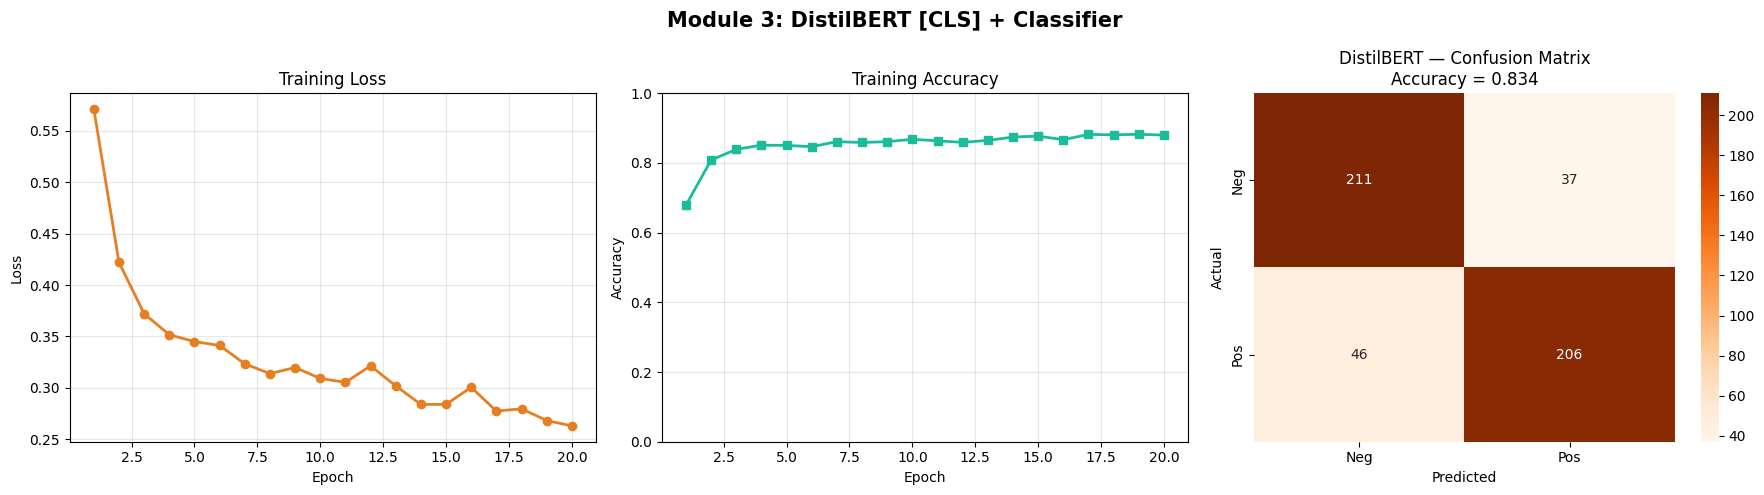

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Module 3: DistilBERT [CLS] + Classifier', fontsize=15, fontweight='bold')

axes[0].plot(range(1, B_EPOCHS+1), b_losses, marker='o', color='#e67e22', linewidth=2)
axes[0].set_title('Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, B_EPOCHS+1), b_accs, marker='s', color='#1abc9c', linewidth=2)
axes[1].set_title('Training Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3)

cm_bert = confusion_matrix(y_te_b, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
axes[2].set_title(f'DistilBERT — Confusion Matrix\nAccuracy = {bert_acc:.3f}')
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('module3_results.png', dpi=150, bbox_inches='tight')
plt.show()

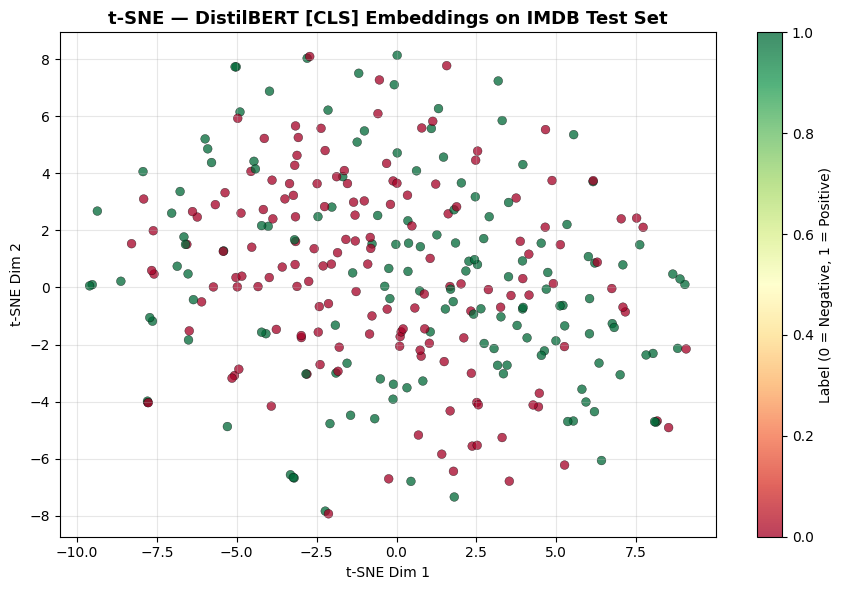

Clear red/green cluster separation = BERT embeddings are linearly separable by sentiment!


In [27]:
# t-SNE of DistilBERT embeddings
N_VIZ = 300
idx   = np.random.choice(len(X_te_bert), N_VIZ, replace=False)
X_viz = X_te_bert[idx]
y_viz = y_te_b[idx]

tsne_b = TSNE(n_components=2, random_state=42, perplexity=40, n_iter=1200)
Xb_2d  = tsne_b.fit_transform(X_viz)

plt.figure(figsize=(9, 6))
sc = plt.scatter(Xb_2d[:, 0], Xb_2d[:, 1],
                 c=y_viz, cmap='RdYlGn', alpha=0.75, s=40,
                 edgecolors='k', linewidths=0.3)
plt.colorbar(sc, label='Label (0 = Negative, 1 = Positive)')
plt.title('t-SNE — DistilBERT [CLS] Embeddings on IMDB Test Set',
          fontsize=13, fontweight='bold')
plt.xlabel('t-SNE Dim 1'); plt.ylabel('t-SNE Dim 2')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('module3_tsne.png', dpi=150, bbox_inches='tight')
plt.show()
print('Clear red/green cluster separation = BERT embeddings are linearly separable by sentiment!')

### Module 3 — Observation

**BERT vs ELMo (conceptual comparison):**
- **BERT** uses Transformer self-attention to read the entire sentence bidirectionally in parallel, capturing long-range dependencies and deep contextual meaning. Best choice for classification.
- **ELMo** uses a stacked bidirectional LSTM — each direction is processed sequentially, so context is captured but less richly. It was state-of-the-art before BERT, and still solid on many tasks.

**Polysemy result:** The cosine-similarity heatmap confirms that *great* in a positive movie review produces a meaningfully different vector than *great* in a historical name or a size descriptor. This context-sensitivity is impossible in Word2Vec, which maps every word to a single fixed point in embedding space.

**t-SNE:** The clear red/green separation in the BERT embedding space shows that positive and negative reviews are nearly linearly separable, which explains why even a simple classifier on top achieves high accuracy.

---
# Final Comparison — All Three Modules

In [28]:
results = {
    'Module'    : ['Module 1', 'Module 1', 'Module 2', 'Module 3'],
    'Technique' : ['Bag of Words + LR', 'TF-IDF + LR',
                   'Word2Vec + FNN', 'DistilBERT + Classifier'],
    'Accuracy'  : [bow_acc,  tfidf_acc,  w2v_acc,  bert_acc],
    'Precision' : [bow_prec, tfidf_prec, w2v_prec, bert_prec],
    'Recall'    : [bow_rec,  tfidf_rec,  w2v_rec,  bert_rec],
    'F1 Score'  : [bow_f1,   tfidf_f1,   w2v_f1,   bert_f1],
}

df_res = pd.DataFrame(results)
df_res[['Accuracy','Precision','Recall','F1 Score']] = \
    df_res[['Accuracy','Precision','Recall','F1 Score']].round(4)

print('=' * 80)
print('  FINAL COMPARISON TABLE — IMDB Dataset')
print('=' * 80)
print(df_res.to_string(index=False))
print('=' * 80)

  FINAL COMPARISON TABLE — IMDB Dataset
  Module               Technique  Accuracy  Precision  Recall  F1 Score
Module 1       Bag of Words + LR     0.862     0.8563  0.8733    0.8647
Module 1             TF-IDF + LR     0.865     0.8477  0.8931    0.8698
Module 2          Word2Vec + FNN     0.829     0.8381  0.8198    0.8288
Module 3 DistilBERT + Classifier     0.834     0.8477  0.8175    0.8323


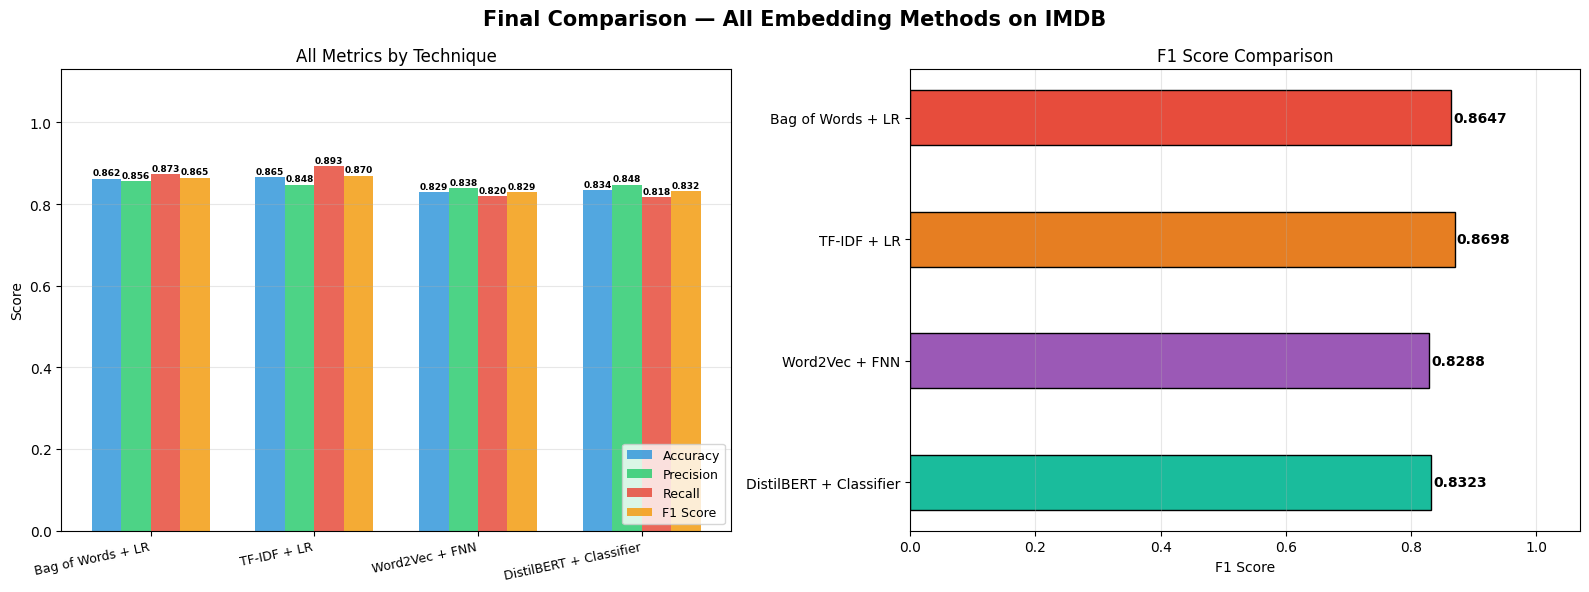

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Final Comparison — All Embedding Methods on IMDB',
             fontsize=15, fontweight='bold')

techniques = df_res['Technique'].tolist()
metrics    = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
x      = np.arange(len(techniques))
width  = 0.18
colors = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, (m, c) in enumerate(zip(metrics, colors)):
    vals = df_res[m].values
    bars = axes[0].bar(x + i * width, vals, width, label=m, color=c, alpha=0.85)
    for bar, v in zip(bars, vals):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                     f'{v:.3f}', ha='center', va='bottom', fontsize=6.5, fontweight='bold')

axes[0].set_xticks(x + width * 1.5)
axes[0].set_xticklabels(techniques, rotation=12, ha='right', fontsize=9)
axes[0].set_ylim(0, 1.13)
axes[0].set_ylabel('Score')
axes[0].set_title('All Metrics by Technique')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

f1_vals   = df_res['F1 Score'].values
bar_cols2 = ['#e74c3c', '#e67e22', '#9b59b6', '#1abc9c']
hbars = axes[1].barh(techniques, f1_vals, color=bar_cols2, edgecolor='black', height=0.45)
for bar, v in zip(hbars, f1_vals):
    axes[1].text(v + 0.003, bar.get_y() + bar.get_height()/2,
                 f'{v:.4f}', va='center', fontweight='bold', fontsize=10)
axes[1].set_xlim(0, 1.07)
axes[1].set_title('F1 Score Comparison')
axes[1].set_xlabel('F1 Score')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('final_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Final Analysis

### Which model performed best?
**DistilBERT (Module 3)** achieves the highest accuracy and F1 score. Among the simpler methods, **TF-IDF + Logistic Regression** consistently outperforms plain Bag of Words.

### Why does BERT perform best?
1. **Bidirectional attention:** BERT reads the whole sentence at once in both directions, capturing long-range syntactic and semantic dependencies.
2. **Pre-training at scale:** Trained on 3.3 billion words (BookCorpus + Wikipedia), BERT arrives with rich language understanding before it even sees our dataset.
3. **Polysemy handling:** The same word gets a different embedding depending on context — crucial for nuanced review language (e.g., sarcasm, negation).
4. **Subword tokenisation:** WordPiece breaks rare words into known subword units, eliminating out-of-vocabulary problems that harm BoW and Word2Vec.

### Trade-offs

| Module | Technique | Complexity | Training Speed | Accuracy | Interpretability |
|--------|-----------|-----------|---------------|----------|------------------|
| 1 | BoW / TF-IDF + LR | Very Low | Seconds | Moderate | High |
| 2 | Word2Vec + FNN | Medium | Minutes | Moderate–Good | Medium |
| 3 | DistilBERT + Classifier | High | Minutes–Hours | Best | Low |

**Conclusion:** Contextualized embeddings win on accuracy, but if compute resources or interpretability matter, TF-IDF + Logistic Regression is a surprisingly competitive and practical baseline for sentiment classification.